# 04 · Convolutional Neural Networks

An MLP treats its input as a flat list of numbers. An image is not a flat list: pixels have **neighbours**, and a pattern (an edge, a loop of a "6") means the same thing wherever it appears. A **convolutional neural network** builds both facts into its wiring. That built-in assumption is called an **inductive bias**, and choosing the right one is often worth more than adding parameters.

What you will build and measure in this notebook:

| Section | Idea | Experiment |
|---|---|---|
| 1-4 | convolution, weight sharing, feature maps | a small CNN vs an MLP on handwritten digits, robustness to shifted images |
| 5 | data augmentation | teach the network that shifted digits are still the same digit |
| 6 | residual connections | a 20-layer plain CNN that cannot learn vs the same depth with skip connections |
| 7 | transfer learning | learn digits 5-9 from a handful of examples by reusing a network trained on 0-4 |
| 8 | efficient convolutions | 1×1 and depthwise-separable convolutions: a fraction of the parameters for a small accuracy cost |

Everything uses **PyTorch** (notebook 02 showed what `loss.backward()` does under the hood) and the training tricks from notebook 03. It runs on a CPU in a few minutes, with no downloads: the digits ship with scikit-learn.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

## 1. Why not an MLP?

A 224×224 RGB image has 150,528 inputs. A single dense layer of 1,000 neurons would need 150 million weights, and it would have to learn "cat ear in the top-left" and "cat ear in the bottom-right" **separately**.

A **convolution** slides a small kernel (e.g. 3×3) over the image, computing a weighted sum at each position:

$$ (I * K)[i,j] = \sum_{u}\sum_{v} I[i+u,\, j+v]\; K[u,v] $$

* **Local connectivity:** each output only looks at a small patch.
* **Weight sharing:** the same kernel is used everywhere, so a feature detector learned once works at every location. A 3×3 kernel has 9 weights regardless of image size.
* **Stacking** convolutions grows the **receptive field**: layer 1 sees edges, layer 2 corners and textures, deeper layers object parts and whole objects.

## 2. Convolution from scratch

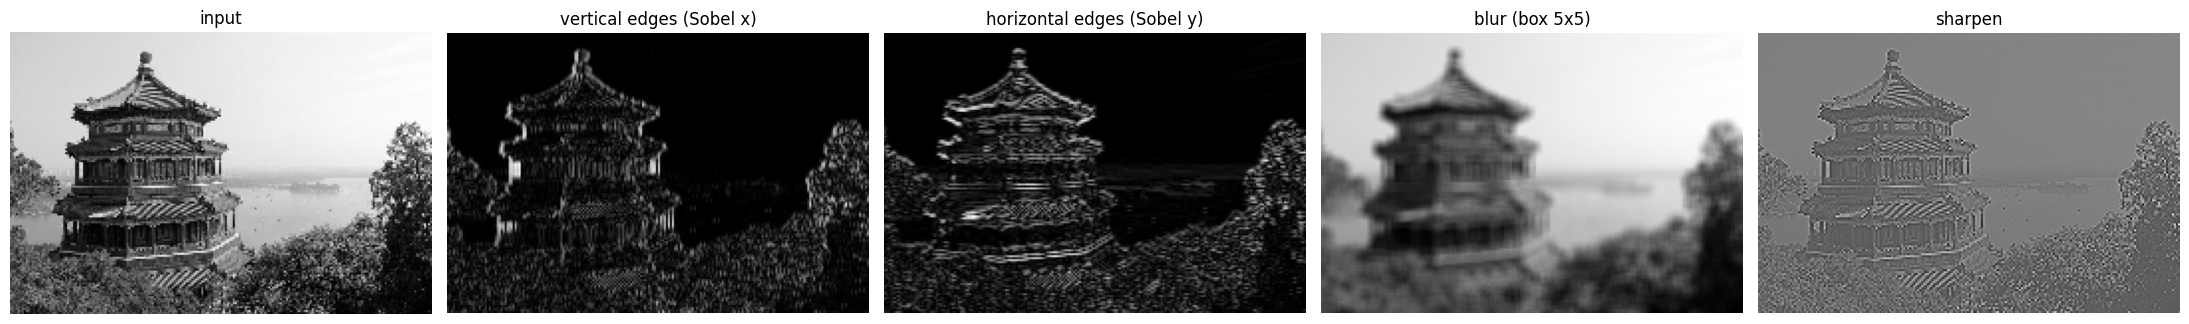

In [2]:
from sklearn.datasets import load_sample_image

def conv2d(img, kernel):
    kh, kw = kernel.shape
    H, W = img.shape
    out = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = (img[i:i + kh, j:j + kw] * kernel).sum()
    return out

img = load_sample_image("china.jpg").mean(axis=2)[::3, ::3] / 255.0   # grayscale, downsampled
kernels = {
    "vertical edges (Sobel x)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "horizontal edges (Sobel y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "blur (box 5x5)": np.ones((5, 5)) / 25,
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
}
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("input")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    out = conv2d(img, k)
    ax.imshow(np.abs(out) if "edges" in name else out, cmap="gray"); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

In a CNN these kernels are **not hand-designed**: they are weights learned by backpropagation. Other building blocks:

* **Channels:** a conv layer has many kernels; each produces one *feature map*. Input RGB = 3 channels; a layer with 32 kernels outputs 32 channels.
* **Padding** keeps the spatial size; **stride** > 1 downsamples.
* **Pooling** (e.g. 2×2 max) halves the resolution, giving some invariance to small shifts and reducing computation.
* At the end, feature maps are flattened (or globally averaged) and fed into a small MLP classifier.

```
image 1×8×8 ─► Conv3×3(16) ─► ReLU ─► Conv3×3(32) ─► ReLU ─► MaxPool2 ─► 32×4×4 ─► flatten ─► Linear(64) ─► ReLU ─► Linear(10) ─► class
```

## 3. Training a CNN on handwritten digits

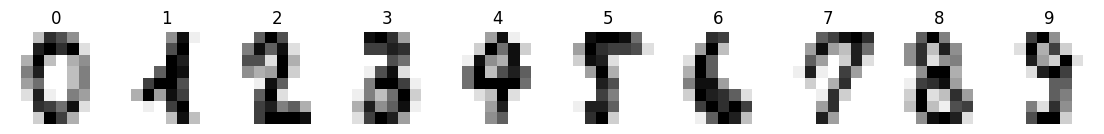

train (1347, 1, 8, 8) test (450, 1, 8, 8)


In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()                                 # 1,797 images of 8x8 pixels, values 0..16
Xd = torch.tensor(digits.images / 16.0, dtype=torch.float32).unsqueeze(1)   # (N, 1, 8, 8)
yd = torch.tensor(digits.target)
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.25, random_state=0, stratify=yd)

fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for d, ax in enumerate(axes):
    ax.imshow(Xtr[ytr == d][0, 0], cmap="gray_r"); ax.set_title(str(d)); ax.axis("off")
plt.show()
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

trained both in 8.2s
CNN  params  38282  test accuracy 98.9%
MLP  params   9610  test accuracy 98.0%


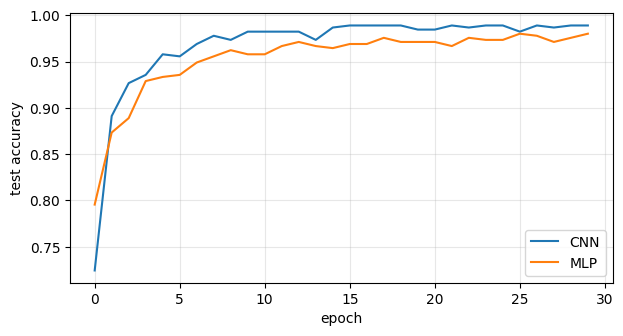

In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, 10)
    def features(self, x):
        a1 = F.relu(self.conv1(x))
        a2 = F.relu(self.conv2(a1))
        return a1, a2
    def forward(self, x):
        _, a2 = self.features(x)
        h = F.max_pool2d(a2, 2).flatten(1)
        return self.fc2(F.relu(self.fc1(h)))

class MLPBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.net(x)

def fit_classifier(model, epochs=30, lr=3e-3, batch=64):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            b = perm[i:i + batch]
            loss = F.cross_entropy(model(Xtr[b]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist.append((model(Xte).argmax(1) == yte).float().mean().item())
    return hist

torch.manual_seed(0)
cnn, mlp = SmallCNN(), MLPBaseline()
t0 = time.time()
h_cnn, h_mlp = fit_classifier(cnn), fit_classifier(mlp)
print(f"trained both in {time.time() - t0:.1f}s")
print(f"CNN  params {count_params(cnn):6d}  test accuracy {h_cnn[-1]:.1%}")
print(f"MLP  params {count_params(mlp):6d}  test accuracy {h_mlp[-1]:.1%}")
plt.figure(figsize=(7, 3.5)); plt.plot(h_cnn, label="CNN"); plt.plot(h_mlp, label="MLP")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Does the convolutional bias help? Shift the test images by one pixel

Both models were trained on centred digits. Shift every test image one pixel right: the MLP sees mostly different input positions, while the CNN's shared kernels still find the same strokes.

In [5]:
def shifted(x, dx):
    return torch.roll(x, shifts=dx, dims=3)

with torch.no_grad():
    for dx in [0, 1, 2]:
        acc_c = (cnn(shifted(Xte, dx)).argmax(1) == yte).float().mean().item()
        acc_m = (mlp(shifted(Xte, dx)).argmax(1) == yte).float().mean().item()
        print(f"shift {dx}px  CNN {acc_c:.1%}   MLP {acc_m:.1%}")

shift 0px  CNN 98.9%   MLP 98.0%
shift 1px  CNN 61.8%   MLP 45.6%
shift 2px  CNN 22.0%   MLP 17.8%


## 4. Looking inside: learned filters and feature maps

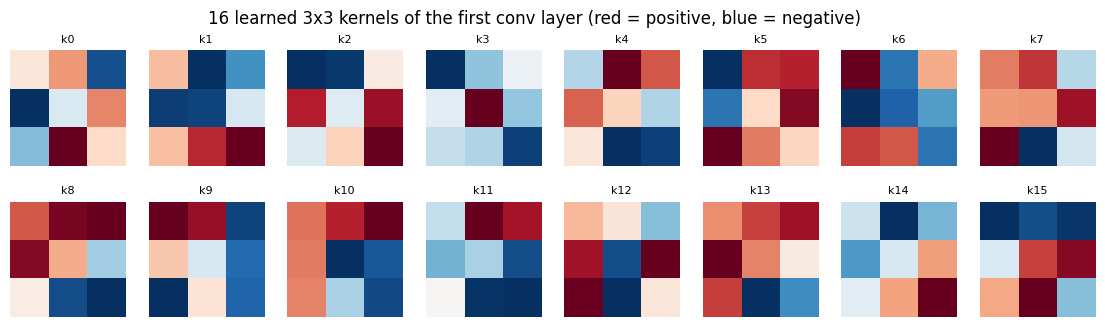

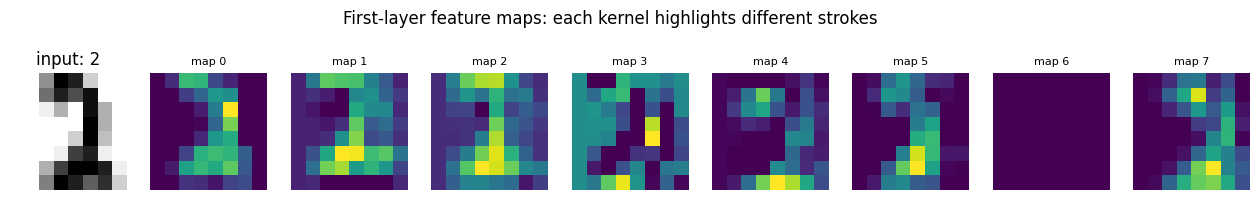

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(14, 3.6))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(cnn.conv1.weight[k, 0].detach(), cmap="RdBu_r"); ax.axis("off"); ax.set_title(f"k{k}", fontsize=8)
fig.suptitle("16 learned 3x3 kernels of the first conv layer (red = positive, blue = negative)"); plt.show()

sample = Xte[:1]
with torch.no_grad():
    a1, a2 = cnn.features(sample)
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
axes[0].imshow(sample[0, 0], cmap="gray_r"); axes[0].set_title(f"input: {yte[0].item()}")
for k, ax in enumerate(axes[1:]):
    ax.imshow(a1[0, k], cmap="viridis"); ax.set_title(f"map {k}", fontsize=8)
for ax in axes: ax.axis("off")
plt.suptitle("First-layer feature maps: each kernel highlights different strokes", y=1.05); plt.show()

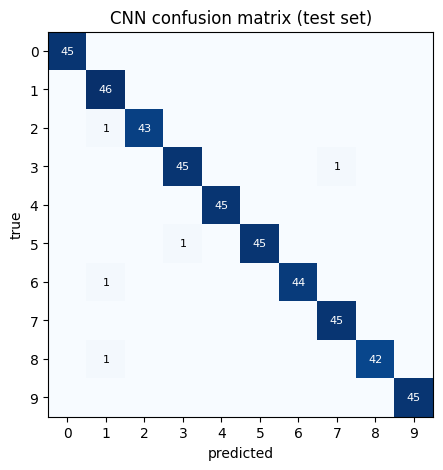

5 mistakes out of 450


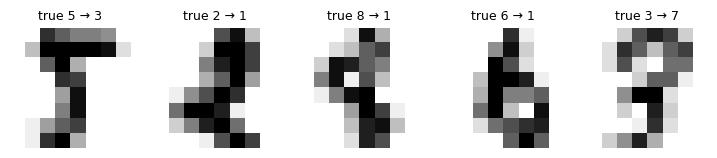

In [7]:
from sklearn.metrics import confusion_matrix
with torch.no_grad():
    pred = cnn(Xte).argmax(1)
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 20 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("CNN confusion matrix (test set)")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); plt.show()

wrong = (pred != yte).nonzero().ravel()
print(f"{len(wrong)} mistakes out of {len(yte)}")
if len(wrong):
    fig, axes = plt.subplots(1, min(8, len(wrong)), figsize=(1.8 * min(8, len(wrong)), 2), squeeze=False)
    for ax, i in zip(axes[0], wrong[:8]):
        ax.imshow(Xte[i, 0], cmap="gray_r"); ax.axis("off"); ax.set_title(f"true {yte[i].item()} → {pred[i].item()}", fontsize=9)
    plt.show()

## 5. Data augmentation: teaching invariances with fake data

The shift test above showed the CNN is *more* robust to moved digits than the MLP, but not immune: the final dense layer still cares about exact positions. The cheapest fix is to **show the network shifted digits during training**. Each mini-batch is randomly translated by up to 2 pixels before the forward pass, so every epoch sees slightly different images.

Augmentation encodes knowledge you already have ("a shifted 3 is still a 3") as data instead of architecture. In practice it is one of the most effective regularisers for vision: random crops, flips, colour jitter, rotations. The only rule is that the transformation must not change the label (flipping a "6" vertically makes a "9"!).

In [8]:
def random_shift(x, max_shift=2):
    # translate each image independently, filling the uncovered border with zeros
    out = torch.zeros_like(x)
    for i in range(len(x)):
        dx, dy = np.random.randint(-max_shift, max_shift + 1, size=2)
        src = x[i, :, max(0, -dy):8 - max(0, dy), max(0, -dx):8 - max(0, dx)]
        out[i, :, max(0, dy):max(0, dy) + src.shape[1], max(0, dx):max(0, dx) + src.shape[2]] = src
    return out

def fit(model, X, y, Xv, yv, epochs=30, lr=3e-3, batch=64, augment=None, params=None):
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            b = perm[i:i + batch]
            xb = augment(X[b]) if augment else X[b]
            loss = F.cross_entropy(model(xb), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist.append((model(Xv).argmax(1) == yv).float().mean().item())
    return hist

def shifted_xy(x, dx, dy):
    # deterministic shift with zero fill (no wrap-around), used for testing
    out = torch.zeros_like(x)
    out[:, :, max(0, dy):8 + min(0, dy), max(0, dx):8 + min(0, dx)] = x[:, :, max(0, -dy):8 - max(0, dy), max(0, -dx):8 - max(0, dx)]
    return out

torch.manual_seed(0); np.random.seed(0)
cnn_aug = SmallCNN()
fit(cnn_aug, Xtr, ytr, Xte, yte, augment=random_shift)

print(f"{'test images shifted by':24s} {'plain CNN':>10s} {'augmented CNN':>14s}")
with torch.no_grad():
    for dx, dy in [(0, 0), (1, 0), (0, 1), (2, 0), (2, 2)]:
        xs = shifted_xy(Xte, dx, dy)
        a = (cnn(xs).argmax(1) == yte).float().mean().item()
        b = (cnn_aug(xs).argmax(1) == yte).float().mean().item()
        print(f"{f'({dx}, {dy}) px':24s} {a:10.1%} {b:14.1%}")

test images shifted by    plain CNN  augmented CNN
(0, 0) px                     98.9%          94.7%
(1, 0) px                     62.0%          95.3%
(0, 1) px                     53.1%          95.6%
(2, 0) px                     22.9%          91.1%
(2, 2) px                      2.2%          85.3%


The augmented network gives up a few points on the original, perfectly centred images (it now spends capacity on positions it will rarely see in this test set) and gains enormously on shifted ones. It never saw a single extra *real* image: the extra knowledge came entirely from the augmentation rule.

## 6. Going deep: why residual connections matter

Deeper networks can represent more complex functions, so a natural move is to stack more layers. Around 2015 researchers noticed something strange: beyond about 20 layers, **plain** deep networks got *worse*, even on the training set. That is not overfitting (notebook 03), it is an optimisation failure: the gradient has to pass through every layer on its way back, and it shrinks or gets scrambled along the way.

The fix proposed in the ResNet paper (He et al., 2015) is almost embarrassingly simple. Instead of asking a block to compute a new representation $H(x)$, ask it for a *correction* to its input:

$$ y = x + F(x) $$

The identity path (the **skip connection**) gives the gradient a highway straight back to early layers: $\partial y / \partial x = I + \partial F / \partial x$, so even if $\partial F/\partial x$ is tiny, the signal survives. A block that has nothing useful to add can simply learn $F \approx 0$ and behave like the identity, so extra depth can no longer hurt. You will meet the same idea again as the **residual stream** of the transformer (notebook 07).

We build two 20-convolution networks that differ **only** in the skip connections and train them for the same number of steps.

plain, 20 conv layers      params 46,730  test accuracy 9.8%  (21s)


residual, 20 conv layers   params 46,730  test accuracy 95.8%  (22s)


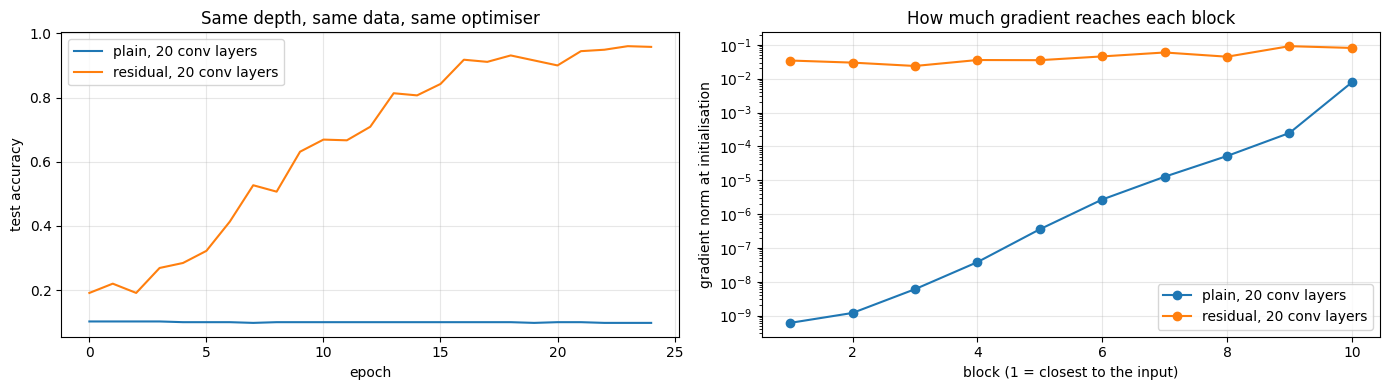

In [9]:
class ConvBlock(nn.Module):
    # two 3x3 convolutions; with residual=True the input is added back to the output
    def __init__(self, ch, residual):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(ch, ch, 3, padding=1), nn.Conv2d(ch, ch, 3, padding=1)
        self.residual = residual
    def forward(self, x):
        out = self.c2(F.relu(self.c1(x)))
        return F.relu(x + out if self.residual else out)

class DeepCNN(nn.Module):
    def __init__(self, n_blocks=10, ch=16, residual=False):
        super().__init__()
        self.stem = nn.Conv2d(1, ch, 3, padding=1)
        self.blocks = nn.Sequential(*[ConvBlock(ch, residual) for _ in range(n_blocks)])
        self.head = nn.Linear(ch, 10)
    def forward(self, x):
        h = self.blocks(F.relu(self.stem(x)))
        return self.head(h.mean(dim=(2, 3)))          # global average pooling

def grad_norms(model):
    # gradient size reaching each block for one batch, from output (right) back to input (left)
    model.zero_grad()
    F.cross_entropy(model(Xtr[:256]), ytr[:256]).backward()
    return [b.c1.weight.grad.norm().item() for b in model.blocks]

curves, grads = {}, {}
for name, res in [("plain, 20 conv layers", False), ("residual, 20 conv layers", True)]:
    torch.manual_seed(0)
    m = DeepCNN(residual=res)
    grads[name] = grad_norms(m)
    t0 = time.time()
    curves[name] = fit(m, Xtr, ytr, Xte, yte, epochs=25, lr=1e-3)
    print(f"{name:26s} params {count_params(m):,}  test accuracy {curves[name][-1]:.1%}  ({time.time() - t0:.0f}s)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name in curves:
    axes[0].plot(curves[name], label=name)
    axes[1].semilogy(range(1, 11), grads[name], marker="o", label=name)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("test accuracy"); axes[0].legend(); axes[0].set_title("Same depth, same data, same optimiser")
axes[1].set_xlabel("block (1 = closest to the input)"); axes[1].set_ylabel("gradient norm at initialisation")
axes[1].set_title("How much gradient reaches each block"); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The right-hand plot is the diagnosis. In the plain network the gradient that reaches the first blocks is orders of magnitude smaller than at the top, so the early layers barely move and the network trains slowly or not at all. With skip connections every block receives a healthy gradient from the start.

Batch normalisation (notebook 03) also helps deep plain networks, and real ResNets use both. The skip connection is the part that made 100+ layer networks routine, and it is now in almost every deep architecture.

## 7. Transfer learning: reuse what another network already learned

Labelled data is expensive. If a network has already learned useful features on a **related** task with plenty of data, we can start from those features instead of from random weights. This is how almost all practical computer vision works: start from a network pre-trained on millions of images, then adapt it to your few hundred.

To keep everything offline we stage the same situation with digits:

* **Source task (lots of data):** classify digits 0 to 4, using all their training images.
* **Target task (very little data):** classify digits 5 to 9, with only $k$ labelled images per class.

Strokes, loops and corners are shared between the two halves, so features learned on 0-4 *should* help on 5-9. Whether they actually do depends on how the source network was trained, so we train it twice: once plainly, and once with the random-shift augmentation from section 5. For each source network we compare three strategies:

| Strategy | What is trained on the target task |
|---|---|
| from scratch | every weight, starting from random |
| frozen features | only a new classifier head; the convolutional layers keep their source weights |
| fine-tuning | everything, starting from the source weights, with a small learning rate |

plain source      (digits 0-4): test accuracy 99.1%


augmented source  (digits 0-4): test accuracy 93.8%



125 target-task trainings in 130s

error rate on digits 5-9                 k=1     k=2     k=5    k=10    k=25
from scratch                           28.8%   20.2%   10.3%    6.2%    2.3%
frozen features, plain source          27.5%   18.9%    7.9%    6.2%    3.2%
fine-tuning, plain source              26.2%   17.9%    8.6%    7.0%    3.4%
frozen features, augmented source      26.7%   17.0%    5.8%    3.8%    1.9%
fine-tuning, augmented source          27.9%   16.1%    7.1%    5.2%    2.3%


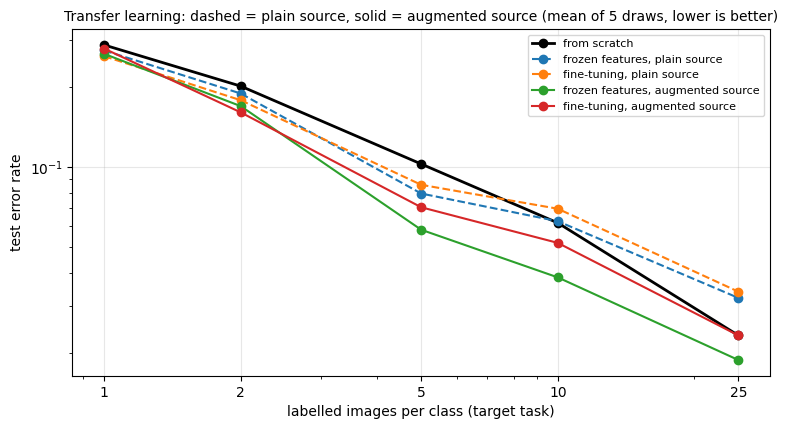

In [10]:
src_tr, src_te = ytr < 5, yte < 5
Xt_te, yt_te = Xte[yte >= 5], yte[yte >= 5] - 5

class SmallCNN5(SmallCNN):
    def __init__(self):
        super().__init__()
        self.fc2 = nn.Linear(64, 5)
    def new_head(self):
        # fresh, randomly initialised classifier on top of the convolutional features
        self.fc1, self.fc2 = nn.Linear(32 * 4 * 4, 64), nn.Linear(64, 5)
        return list(self.fc1.parameters()) + list(self.fc2.parameters())

sources = {}
for name, aug in [("plain source", None), ("augmented source", random_shift)]:
    torch.manual_seed(0); np.random.seed(0)
    net = SmallCNN5()
    h = fit(net, Xtr[src_tr], ytr[src_tr], Xte[src_te], yte[src_te], epochs=30, augment=aug)
    sources[name] = {k: v.clone() for k, v in net.state_dict().items()}
    print(f"{name:17s} (digits 0-4): test accuracy {h[-1]:.1%}")

def few_shot_split(k, seed):
    g = np.random.default_rng(seed)
    idx = []
    for d in range(5, 10):
        pool = np.where((ytr == d).numpy())[0]
        idx += list(g.choice(pool, size=k, replace=False))
    idx = torch.tensor(idx)
    return Xtr[idx], ytr[idx] - 5

def run(strategy, k, seed, source=None):
    torch.manual_seed(seed)
    m = SmallCNN5()
    Xk, yk = few_shot_split(k, seed)
    if strategy == "from scratch":
        return fit(m, Xk, yk, Xt_te, yt_te, epochs=60, lr=3e-3, batch=16)[-1]
    m.load_state_dict(sources[source])
    head = m.new_head()                                   # the old head only knew digits 0-4
    if strategy == "frozen features":
        for p in list(m.conv1.parameters()) + list(m.conv2.parameters()):
            p.requires_grad = False
        return fit(m, Xk, yk, Xt_te, yt_te, epochs=60, lr=3e-3, batch=16, params=head)[-1]
    return fit(m, Xk, yk, Xt_te, yt_te, epochs=60, lr=1e-3, batch=16)[-1]   # fine-tuning: smaller learning rate

ks = [1, 2, 5, 10, 25]
runs = [("from scratch", None)] + [(s, src) for src in sources for s in ["frozen features", "fine-tuning"]]
t0 = time.time()
results = {}
for s, src in runs:
    label = s if src is None else f"{s}, {src}"
    results[label] = [np.mean([run(s, k, seed, src) for seed in range(5)]) for k in ks]
print(f"\n{len(runs) * len(ks) * 5} target-task trainings in {time.time() - t0:.0f}s\n")

print(f"{'error rate on digits 5-9':36s}" + "".join(f"{f'k={k}':>8s}" for k in ks))
for label, acc in results.items():
    print(f"{label:36s}" + "".join(f"{1 - a:8.1%}" for a in acc))
plt.figure(figsize=(9, 4.5))
for label, acc in results.items():
    style = dict(color="k", lw=2) if label == "from scratch" else dict(ls="--" if "plain" in label else "-")
    plt.plot(ks, [1 - a for a in acc], marker="o", label=label, **style)
plt.xscale("log"); plt.yscale("log"); plt.xticks(ks, ks); plt.xlabel("labelled images per class (target task)"); plt.ylabel("test error rate")
plt.title("Transfer learning: dashed = plain source, solid = augmented source (mean of 5 draws, lower is better)", fontsize=10)
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

The dashed lines are the uncomfortable part of the result. Features from the **plain** source network help a little with one to five examples per class, but by 10 examples they are no better than training from scratch, and by 25 they are *worse*: they are specialised to the exact, centred digits 0-4 they were trained on, and starting from them gets in the way once the target task has enough data of its own. Frozen features from the **augmented** source network beat training from scratch at every data size, and with 5 examples per class they roughly halve the error.

Notice the twist in the first two printed lines: the augmented source network is *worse* at its own task (it gave up accuracy on perfectly centred test digits, as in section 5), yet it is the better starting point for a new one. Same architecture, same source data, same target task: augmentation forced the source network to learn features that are not tied to one exact position, and general features are the ones that transfer. A model's score on its original task is a poor guide to how useful its features are elsewhere.

Two more honest caveats about this toy setup:

* A CNN on 8×8 digits is already a strong learner from scratch (its inductive bias does a lot of work), so even the good gap is moderate. With real photos and a network pre-trained on millions of varied images, the gap is usually much larger.
* Pre-trained models used in practice are trained with heavy augmentation on huge, diverse datasets, which is exactly why their features transfer so well. "Transfer learning works" is really a claim about *how the source model was trained*.

Rules of thumb that carry over to real projects:

* **Tiny target dataset, similar domain:** freeze the backbone, train only a new head.
* **More target data:** fine-tune everything with a learning rate several times smaller than for training from scratch, so the useful features are adjusted rather than overwritten.
* **Very different domain** (say, X-rays from a network pre-trained on holiday photos): early layers (edges, textures) still transfer well, late layers less so.

## 8. Efficient convolutions: 1×1 and depthwise-separable

A standard $3\times3$ convolution from $C_{in}$ to $C_{out}$ channels has $9\, C_{in} C_{out}$ weights: every output channel looks at every input channel at every spatial offset. Two cheaper building blocks are used throughout modern networks (Inception, MobileNet, EfficientNet):

* **1×1 convolution:** a tiny dense layer applied at every pixel. It mixes channels but not space, and is the standard way to shrink or grow the number of channels cheaply.
* **Depthwise-separable convolution:** split the job in two. First a *depthwise* $3\times3$ conv filters each channel on its own ($9\, C_{in}$ weights), then a *pointwise* $1\times1$ conv mixes channels ($C_{in} C_{out}$ weights). For $C_{in} = C_{out} = 64$ that is about 8× fewer weights and multiply-adds.

In [11]:
def sep_conv(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cin, 3, padding=1, groups=cin),   # depthwise: one 3x3 filter per channel
                         nn.Conv2d(cin, cout, 1))                         # pointwise: mix channels

for cin, cout in [(16, 32), (64, 64), (256, 256)]:
    std, sep = nn.Conv2d(cin, cout, 3, padding=1), sep_conv(cin, cout)
    print(f"{cin:3d} -> {cout:3d} channels   standard 3x3: {count_params(std):7,d} params   "
          f"depthwise-separable: {count_params(sep):6,d}   ratio {count_params(std) / count_params(sep):.1f}x")

class SmallSepCNN(SmallCNN):
    # identical to SmallCNN except the second convolution is depthwise-separable
    def __init__(self):
        super().__init__()
        self.conv2 = sep_conv(16, 32)

torch.manual_seed(0)
sep_net = SmallSepCNN()
h_sep = fit(sep_net, Xtr, ytr, Xte, yte)
conv_params = lambda m: sum(p.numel() for n, p in m.named_parameters() if n.startswith("conv"))
print(f"\nstandard CNN   conv params {conv_params(cnn):5d}   test accuracy {h_cnn[-1]:.1%}")
print(f"separable CNN  conv params {conv_params(sep_net):5d}   test accuracy {h_sep[-1]:.1%}")

 16 ->  32 channels   standard 3x3:   4,640 params   depthwise-separable:    704   ratio 6.6x
 64 ->  64 channels   standard 3x3:  36,928 params   depthwise-separable:  4,800   ratio 7.7x
256 -> 256 channels   standard 3x3: 590,080 params   depthwise-separable: 68,352   ratio 8.6x



standard CNN   conv params  4800   test accuracy 98.9%
separable CNN  conv params   864   test accuracy 96.7%


The separable network uses several times fewer convolution weights for a small drop in accuracy. At the channel counts of real networks the saving approaches an order of magnitude, which is a big part of what makes neural networks fast enough to run on phones. Architectures like MobileNet then win back the accuracy by spending the savings on more channels or layers.

**Where CNNs went next:** LeNet (1998) → AlexNet (2012, the deep learning breakthrough on ImageNet) → VGG → **ResNet** (2015, residual connections) → MobileNet / EfficientNet (efficient blocks, careful scaling) → vision transformers, which replace convolutions with attention on image patches (notebook 07). Notebook 09 takes CNNs beyond "one label per image": segmentation, detection and learned similarity.

## Key takeaways

* A convolution is a small filter slid over the image. **Weight sharing** makes CNNs data-efficient and robust to where a pattern appears.
* **Data augmentation** teaches invariances you already know about, for free.
* **Residual connections** ($y = x + F(x)$) keep gradients alive through depth, which is what made very deep networks trainable.
* **Transfer learning** reuses features from a data-rich task, and wins most when your own labelled data is scarce.
* **1×1 and depthwise-separable** convolutions cut parameters and compute by large factors for a small loss in accuracy.

## Exercises

1. Add `nn.BatchNorm2d` after each convolution in the *plain* 20-layer network (section 6). How much of the gap to the residual network does it close?
2. Increase the depth to 40 convolutions (`n_blocks=20`). What happens to each network?
3. In section 5, add random rotations of ±15° as augmentation (hint: `torch.rot90` only does 90°; try `torch.nn.functional.affine_grid`). Does it help on the original, unshifted test set?
4. Transfer in the other direction: pre-train on 5-9 and adapt to 0-4. Is the benefit symmetric?
5. Train the source network on digits 0-4 for 5 epochs instead of 30 (with augmentation). Do undertrained source features transfer better or worse than fully trained ones?
6. Fine-tune with a learning rate of 1e-2. What happens with 2 examples per class, and why?